Наиболее протяженный участок: от (41, 165) до (222, 69), длина = 204.88 пикс.


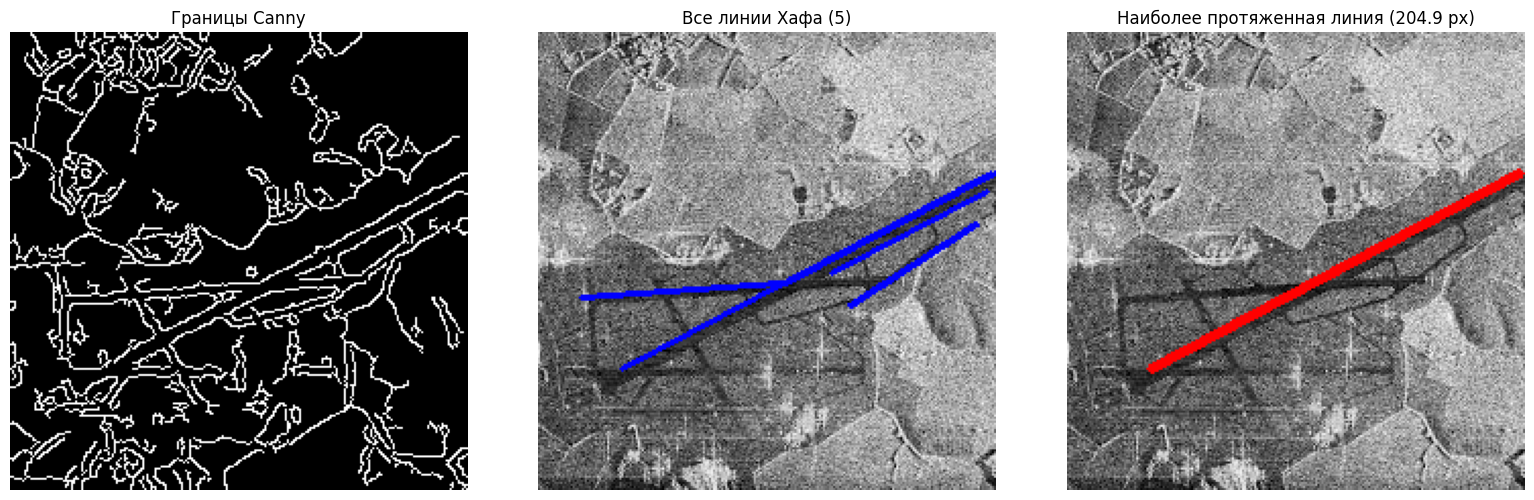

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Загрузка изображения sar_3.jpg
img_bgr = cv2.imread('sar_3.jpg')
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

# 2. Фильтрация спекл-шума перед детектором границ
blurred = cv2.GaussianBlur(img_gray, (5, 5), 1.5)

# 3. Детектирование границ оператором Canny
edges = cv2.Canny(blurred, 50, 150, apertureSize=3)

# 4. Вероятностное преобразование Хафа (HoughLinesP)
lines_p = cv2.HoughLinesP(
    edges,
    rho=1,
    theta=np.pi / 180,
    threshold=80,
    minLineLength=50,
    maxLineGap=10
)

# Создаем копии для отрисовки
img_all_lines = img_bgr.copy()
img_longest_line = img_bgr.copy()

longest_line = None
max_len = 0.0

if lines_p is not None:
    for line in lines_p:
        x1, y1, x2, y2 = line[0]
        length = np.hypot(x2 - x1, y2 - y1)

        # Отрисовка всех обнаруженных линий синим цветом
        cv2.line(img_all_lines, (x1, y1), (x2, y2), (255, 0, 0), 2)

        if length > max_len:
            max_len = length
            longest_line = (x1, y1, x2, y2)

# Выделение наиболее протяженного участка красным цветом
if longest_line is not None:
    x1, y1, x2, y2 = longest_line
    cv2.line(img_longest_line, (x1, y1), (x2, y2), (0, 0, 255), 4)
    print(f"Наиболее протяженный участок: от ({x1}, {y1}) до ({x2}, {y2}), длина = {max_len:.2f} пикс.")

# Визуализация результатов
plt.figure(figsize=(16, 5))
plt.subplot(1, 3, 1)
plt.imshow(edges, cmap='gray')
plt.title('Границы Canny')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(img_all_lines, cv2.COLOR_BGR2RGB))
plt.title(f'Все линии Хафа ({len(lines_p) if lines_p is not None else 0})')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(img_longest_line, cv2.COLOR_BGR2RGB))
plt.title(f'Наиболее протяженная линия ({max_len:.1f} px)')
plt.axis('off')

plt.tight_layout()
plt.show()

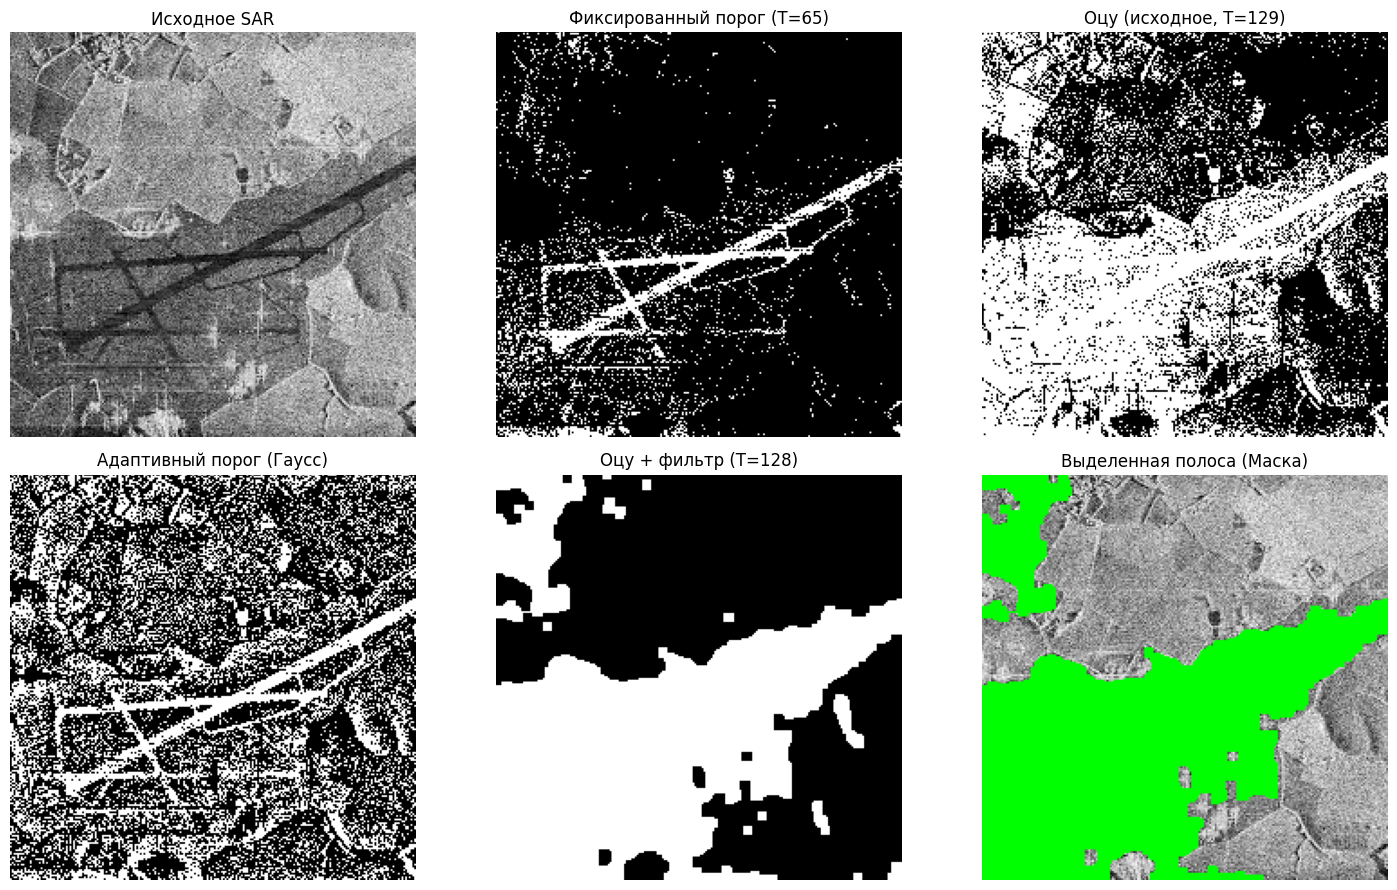

In [2]:
# Предварительная фильтрация спекл-шума для подавления ложных всплесков
filtered_img = cv2.medianBlur(img_gray, 5)

# 1. Фиксированный глобальный порог (инвертированный, чтобы темная полоса стала белой)
T_fixed = 65
_, bin_fixed = cv2.threshold(img_gray, T_fixed, 255, cv2.THRESH_BINARY_INV)

# 2. Глобальная бинаризация методом Оцу на исходном снимке
otsu_val_raw, bin_otsu_raw = cv2.threshold(img_gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# 3. Адаптивная бинаризация по Гауссу
bin_adaptive = cv2.adaptiveThreshold(
    img_gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY_INV, 51, 10
)

# 4. Метод Оцу на отфильтрованном изображении + морфологические операции
otsu_val_filt, bin_otsu_filt = cv2.threshold(filtered_img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# Морфологическое замыкание и открытие
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
bin_morph = cv2.morphologyEx(bin_otsu_filt, cv2.MORPH_OPEN, kernel)
bin_morph = cv2.morphologyEx(bin_morph, cv2.MORPH_CLOSE, kernel)

# Фильтрация по площади связных компонентов для выделения именно полосы
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(bin_morph)
road_mask = np.zeros_like(bin_morph)

# Отсекаем фон (label 0) и берем только крупные вытянутые компоненты
for label in range(1, num_labels):
    area = stats[label, cv2.CC_STAT_AREA]
    if area > 1000:  # Порог отсечения мелкого шума
        road_mask[labels == label] = 255

# Наложение выделенной полосы на исходное изображение
result_overlay = img_bgr.copy()
result_overlay[road_mask == 255] = [0, 255, 0]  # Зеленая маска

# Сравнительный вывод всех алгоритмов
titles = [
    'Исходное SAR',
    f'Фиксированный порог (T={T_fixed})',
    f'Оцу (исходное, T={int(otsu_val_raw)})',
    'Адаптивный порог (Гаусс)',
    f'Оцу + фильтр (T={int(otsu_val_filt)})',
    'Выделенная полоса (Маска)'
]

images = [
    cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB),
    bin_fixed,
    bin_otsu_raw,
    bin_adaptive,
    bin_morph,
    cv2.cvtColor(result_overlay, cv2.COLOR_BGR2RGB)
]

plt.figure(figsize=(15, 9))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    if len(images[i].shape) == 2:
        plt.imshow(images[i], cmap='gray')
    else:
        plt.imshow(images[i])
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()